In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import rcParams
%matplotlib inline
plt.style.use('dark_background')
import warnings
warnings.filterwarnings('ignore')

In [5]:
df = pd.read_csv(r"C:\Users\Damil\Downloads/adult.csv", encoding='latin-1')

In [5]:
df.shape

(32561, 15)

In [6]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education.num',
       'marital.status', 'occupation', 'relationship', 'race', 'sex',
       'capital.gain', 'capital.loss', 'hours.per.week', 'native.country',
       'income'],
      dtype='str')

In [10]:
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [9]:
df.tail()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
32556,22,Private,310152,Some-college,10,Never-married,Protective-serv,Not-in-family,White,Male,0,0,40,United-States,<=50K
32557,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32558,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32559,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
32560,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


In [11]:
df = df.drop(columns=['education.num', 'race'])

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   marital.status  32561 non-null  str  
 5   occupation      32561 non-null  str  
 6   relationship    32561 non-null  str  
 7   sex             32561 non-null  str  
 8   capital.gain    32561 non-null  int64
 9   capital.loss    32561 non-null  int64
 10  hours.per.week  32561 non-null  int64
 11  native.country  32561 non-null  str  
 12  income          32561 non-null  str  
dtypes: int64(5), str(8)
memory usage: 5.5 MB


In [18]:
word_column = [column for column in df.columns if df[column].dtypes =='string']
print(word_column)

['workclass', 'education', 'marital.status', 'occupation', 'relationship', 'sex', 'native.country', 'income']


In [19]:
word_column = [column for column in df.columns if df[column].dtypes !='string']
print(word_column)

['age', 'fnlwgt', 'capital.gain', 'capital.loss', 'hours.per.week']


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,32561.0,38.581647,13.640433,17.0,28.0,37.0,48.0,90.0
fnlwgt,32561.0,189778.366512,105549.977697,12285.0,117827.0,178356.0,237051.0,1484705.0
education.num,32561.0,10.080679,2.572720,1.0,9.0,10.0,12.0,16.0
capital.gain,32561.0,1077.648844,7385.292085,0.0,0.0,0.0,0.0,99999.0
capital.loss,32561.0,87.303830,402.960219,0.0,0.0,0.0,0.0,4356.0
hours.per.week,32561.0,40.437456,12.347429,1.0,40.0,40.0,45.0,99.0


In [9]:
df.groupby("income")['age'].mean()

income
<=50K    36.783738
>50K     44.249841
Name: age, dtype: float64

In [11]:
def get_groupby_stats(category, numbers):
    groupby_df = df[['income','age']].groupby("income").mean().dropna()
    print(groupby_df.head())

In [14]:
get_groupby_stats('income', 'age')

              age
income           
<=50K   36.783738
>50K    44.249841


In [17]:
show_columns = ['age', 'hours.per.week']
df.groupby(['income'])[show_columns].agg(['mean', 'std', 'max', 'min'])

age                    hours.per.week                   
             mean        std max min           mean        std max min
income                                                                
<=50K   36.783738  14.020088  90  17      38.840210  12.318995  99   1
>50K    44.249841  10.519028  90  19      45.473026  11.012971  99   1

In [18]:
df.nunique()

age                  73
workclass             9
fnlwgt            21648
education            16
education.num        16
marital.status        7
occupation           15
relationship          6
race                  5
sex                   2
capital.gain        119
capital.loss         92
hours.per.week       94
native.country       42
income                2
dtype: int64

In [20]:
print(df["age"].value_counts())
print(df["race"].value_counts())

age
36    898
31    888
34    886
23    877
35    876
     ... 
83      6
88      3
85      3
86      1
87      1
Name: count, Length: 73, dtype: int64
race
White                 27816
Black                  3124
Asian-Pac-Islander     1039
Amer-Indian-Eskimo      311
Other                   271
Name: count, dtype: int64


<Axes: xlabel='age', ylabel='Count'>

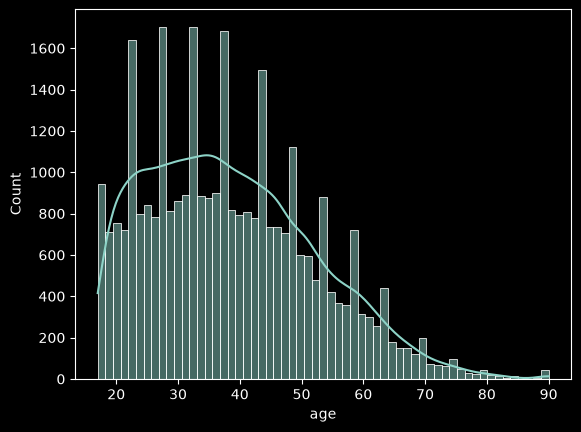

In [21]:
sns.histplot(data=df['age'],kde=True)

<Axes: xlabel='income', ylabel='Count'>

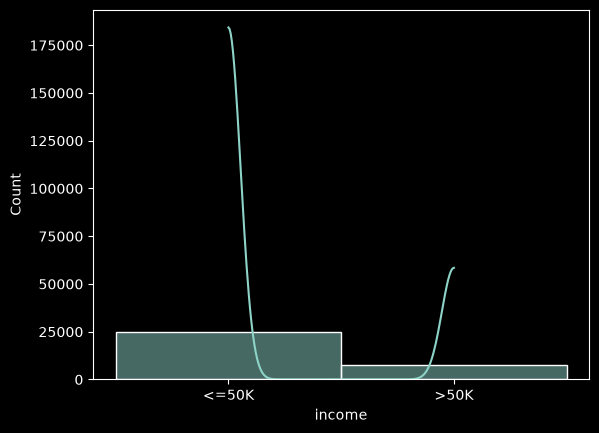

In [23]:
sns.histplot(data=df['income'],kde=True)

<Axes: xlabel='education'>

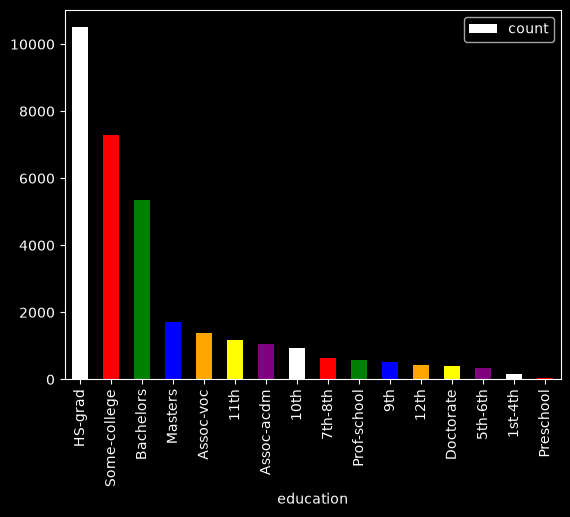

In [6]:
df['education'].value_counts()
##Let us plot the bar chart for education.
colors = ["white", "red", "green", "blue", "orange", "yellow", "purple"]
df.education.value_counts().plot.bar(color=colors, legend=True)

<Axes: xlabel='age', ylabel='Count'>

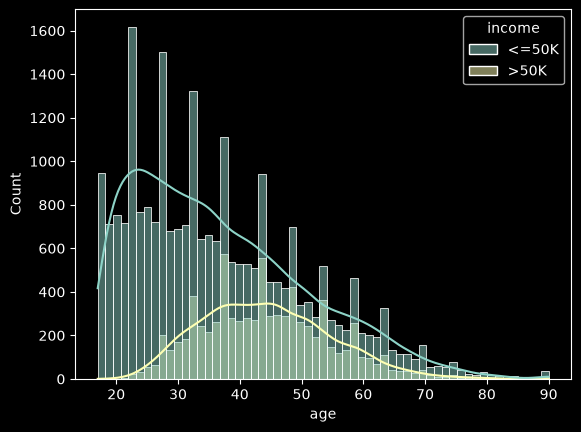

In [7]:
sns.histplot(data=df,kde=True,x='age',hue='income')

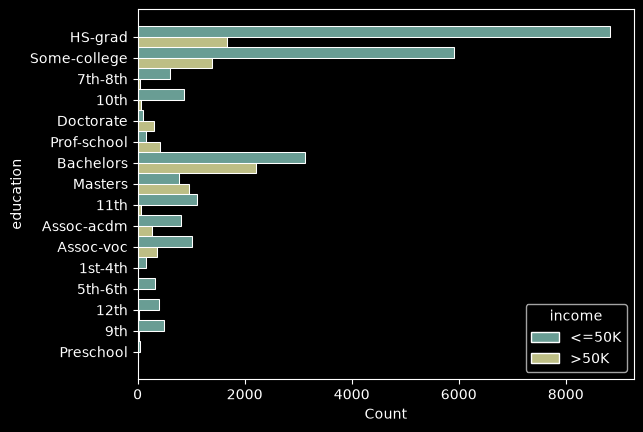

In [8]:
sns.histplot(data=df,y='education', hue='income',multiple="dodge");